<a href="https://colab.research.google.com/github/alpakarpenko/aeaeae/blob/main/%D0%9A%D0%B0%D1%80%D0%BF%D0%B5%D0%BD%D0%BA%D0%BE_Tutorial3_Data_simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Цель этого занятия -- научиться симулировать данные, которые выглядят биологически правдоподобно, чтобы проверять на них методы анализа!

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_eeg_data(EEG, channel=0, fig_num=1):
    """
    Функция для построения графиков EEG данных

    Параметры:
    EEG - словарь с данными EEG
    channel - номер канала для отображения (по умолчанию 0)
    fig_num - номер фигуры (по умолчанию 1)
    """

    plt.figure(fig_num, figsize=(15, 10))

    # 1. График отдельного треила (пробы)
    plt.subplot(2, 2, 1)
    # Отображаем данные одного канала в одной пробе (trial)
    plt.plot(EEG['times'], EEG['data'][channel, :, 0])
    plt.title(f'Отдельная проба (канал {channel})')
    plt.xlabel('Время (сек)')
    plt.ylabel('Амплитуда')
    plt.grid(True, alpha=0.3)

    # 2. График ERP (Event-Related Potential) - усредненный сигнал
    plt.subplot(2, 2, 2)
    # Усредняем все пробы по времени для получения ERP
    # axis=1 означает усреднение по пробам (третье измерение)
    erp = np.mean(EEG['data'][channel, :, :], axis=1)
    plt.plot(EEG['times'], erp)
    plt.title(f'ERP (канал {channel})')
    plt.xlabel('Время (сек)')
    plt.ylabel('Амплитуда')
    plt.grid(True, alpha=0.3)

    # 3. Статический спектр мощности
    plt.subplot(2, 2, 3)
    # Вычисляем быстрое преобразование Фурье для одной пробы
    data_fft = np.fft.fft(EEG['data'][channel, :, 0])
    # Получаем частоты для FFT (в Герцах)
    freqs = np.fft.fftfreq(EEG['pnts'], 1/EEG['srate'])
    # Берем только положительные частоты (первую половину)
    pos_freqs = freqs[:EEG['pnts']//2]
    # Вычисляем спектр мощности как квадрат модуля FFT (квадрат амплитуды)
    pos_spectrum = np.abs(data_fft[:EEG['pnts']//2])**2
    plt.plot(pos_freqs, pos_spectrum)
    plt.title('Статический спектр мощности')
    plt.xlabel('Частота (Гц)')
    plt.ylabel('Мощность')
    plt.grid(True, alpha=0.3)
    plt.xlim(0, 50)  # Ограничиваем диапазон частот для лучшей видимости

    # 4. Динамический спектр мощности (спектрограмма)
    plt.subplot(2, 2, 4)
    # Строим спектрограмму - показывает как спектр меняется во времени
    # Fs=EEG['srate'] указывает частоту дискретизации
    Pxx, freqs, bins, im = plt.specgram(EEG['data'][channel, :, 0],
                                       Fs=EEG['srate'],
                                       cmap='viridis')
    plt.title('Динамический спектр мощности')
    plt.xlabel('Время (сек)')
    plt.ylabel('Частота (Гц)')
    # Добавляем цветовую шкалу для интенсиновости
    plt.colorbar(im, label='Мощность (дБ)')

    # Автоматически подбираем отступы между subplots
    plt.tight_layout()
    plt.show()

#1. Белый шум

1) White noise


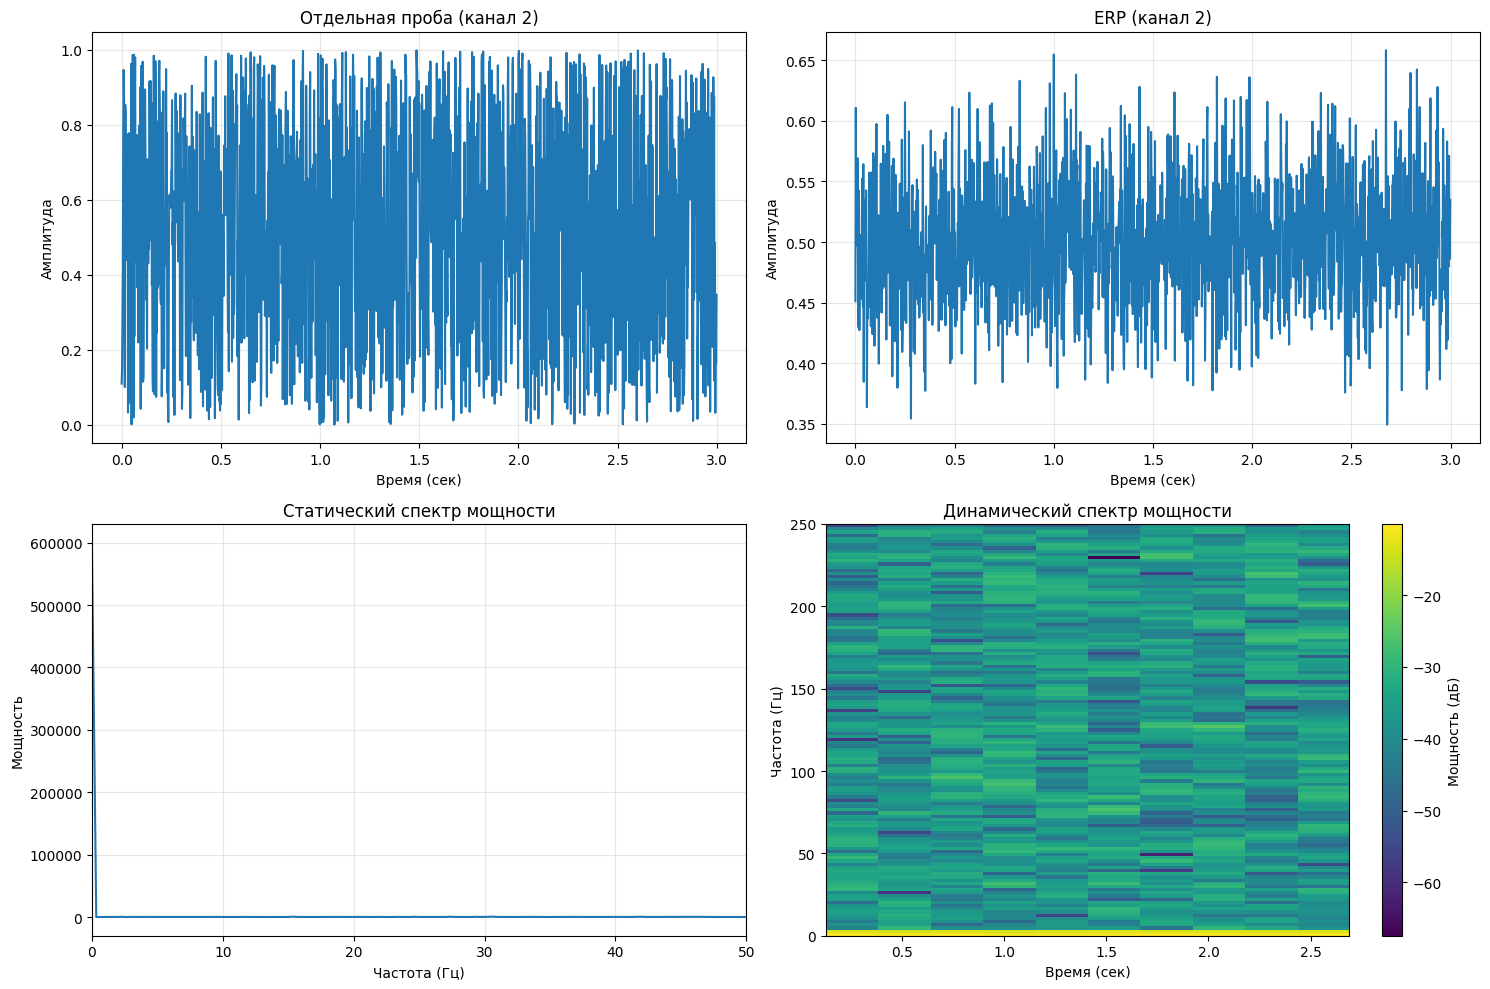

In [ ]:
# 1) White noise
print("1) White noise")

# Specify EEG parameters
EEG = {
    'srate': 500,    # Частота дискретизации в Герцах (сколько отсчетов в секунду)
    'pnts': 1500,    # Количество временных точек в одной пробе
    'trials': 30,    # Количество проб
    'nbchan': 23     # Количество каналов (электродов)
}

# Создаем временной вектор
# np.arange(EEG['pnts']) создает массив [0, 1, 2, ..., 1499]
# Делим на частоту дискретизации чтобы получить время в секундах
EEG['times'] = np.arange(EEG['pnts']) / EEG['srate']

# Генерируем данные как белый шум
# np.random.randn создает массив случайных чисел из нормального распределения
# Размерность: (каналы × временные точки × пробы)
amplit = [1]
for a in amplit:
  EEG['data'] = a * np.random.rand(EEG['nbchan'], EEG['pnts'], EEG['trials']) # Добавьте размерность данных

# Строим графики используя нашу функцию
plot_eeg_data(EEG, channel=2, fig_num=1)

Q: Как амплитуда шума влияет на получающиеся графики?

Амплитуда влияет в первую очередь на значения на осях. При нормальной амплитуде значения на графиках отдельной пробы и ВП варьируются от -3 до 3, а значения мощности на статической и динамической спектрограммах от 0 до 10000 и от -60 до -20. Увеличение амплитуды приводит к увеличению диапазона на графиках, уменьшению мощности на статической спектрограмме и сдвигу мощности в положительную сторону на динамической. Уменьшение амплитуды в коде приводит к противоположному.

Q: Меняются ли результаты, если использовать нормально распределенный шум вместо равномерно распределенного?

Рассматриваемый тут шум уже нормально распределён, поскольку используется np.random.randn(). Если сделать его равномерно распределённым (убрать одну букву n), в графиках будет больше экстремальных значений,а спектрограммы сместятся в сторону более низких частот и высоких мощностей.

Q: Различаются ли результаты для разных каналов? Почему да или почему нет?

Есть различия между формами графиков, но не в основных свойствах, так как графики представляют из себя случайный набор данных в рамках заданных параметров, на каждом канале одинаково рандомный белый шум

# 2. Розовый шум

2) Pink noise
Графики для ed=30


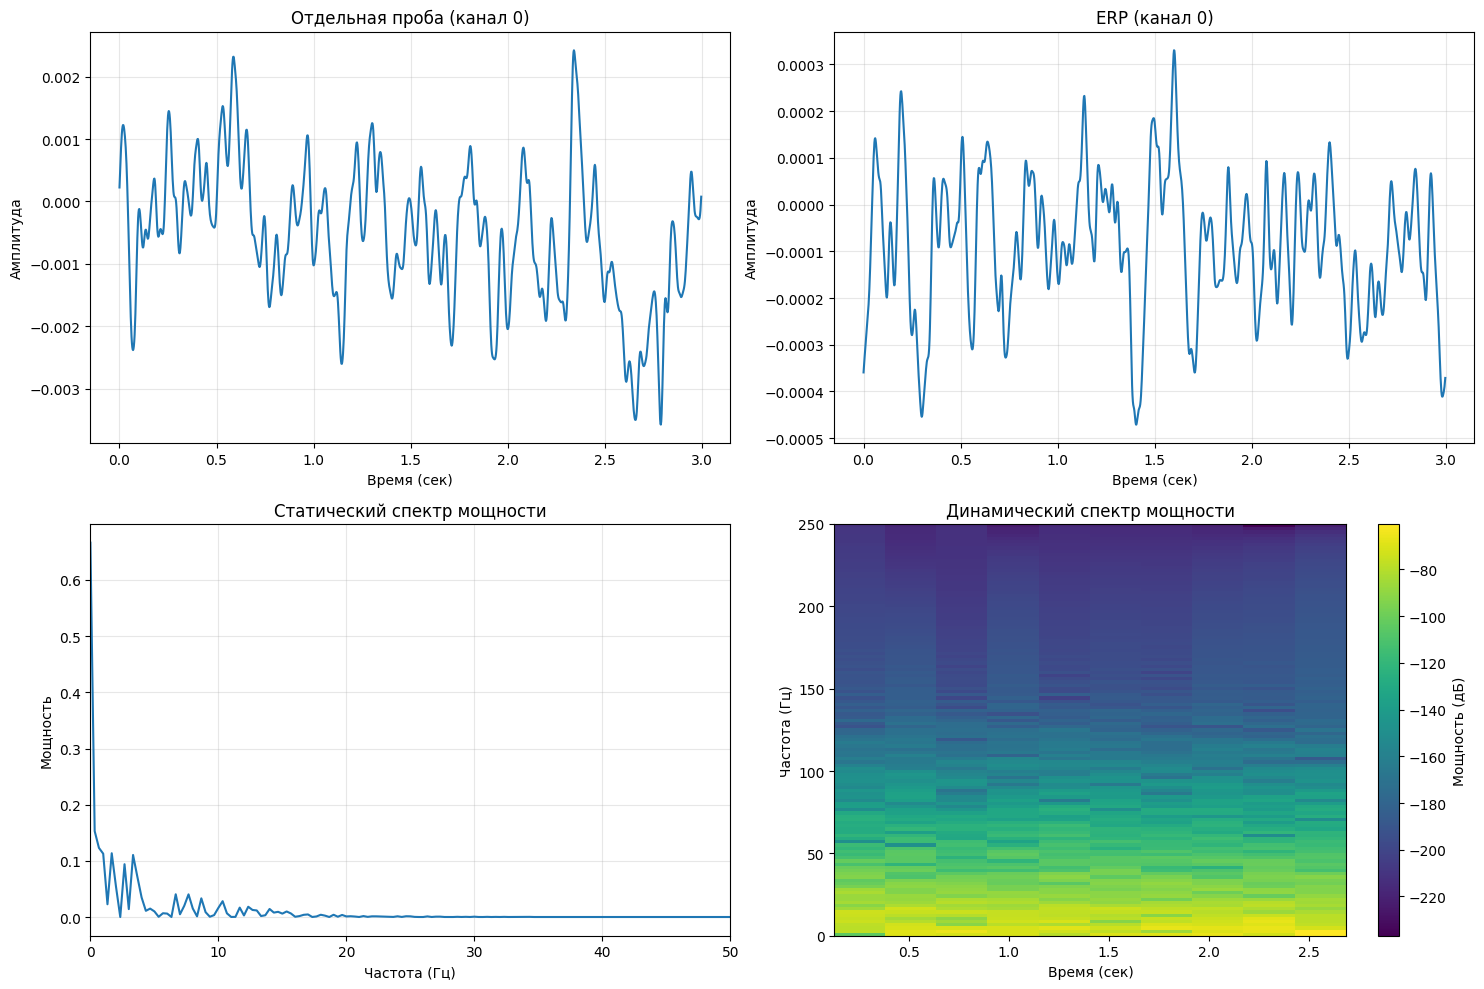

Графики для ed=50


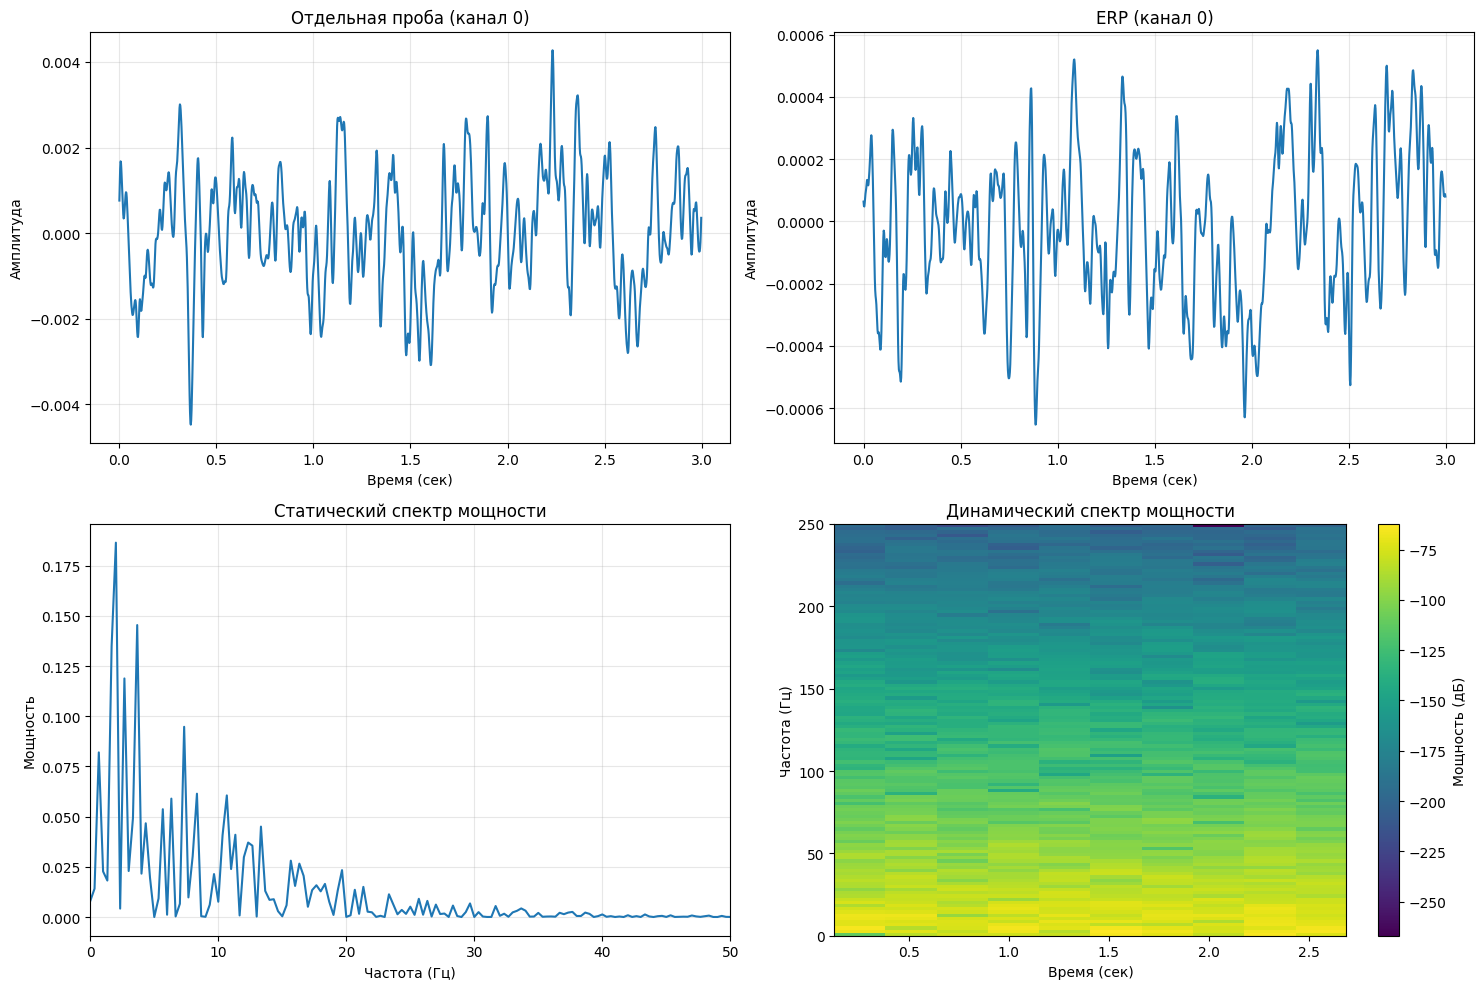

Графики для ed=70


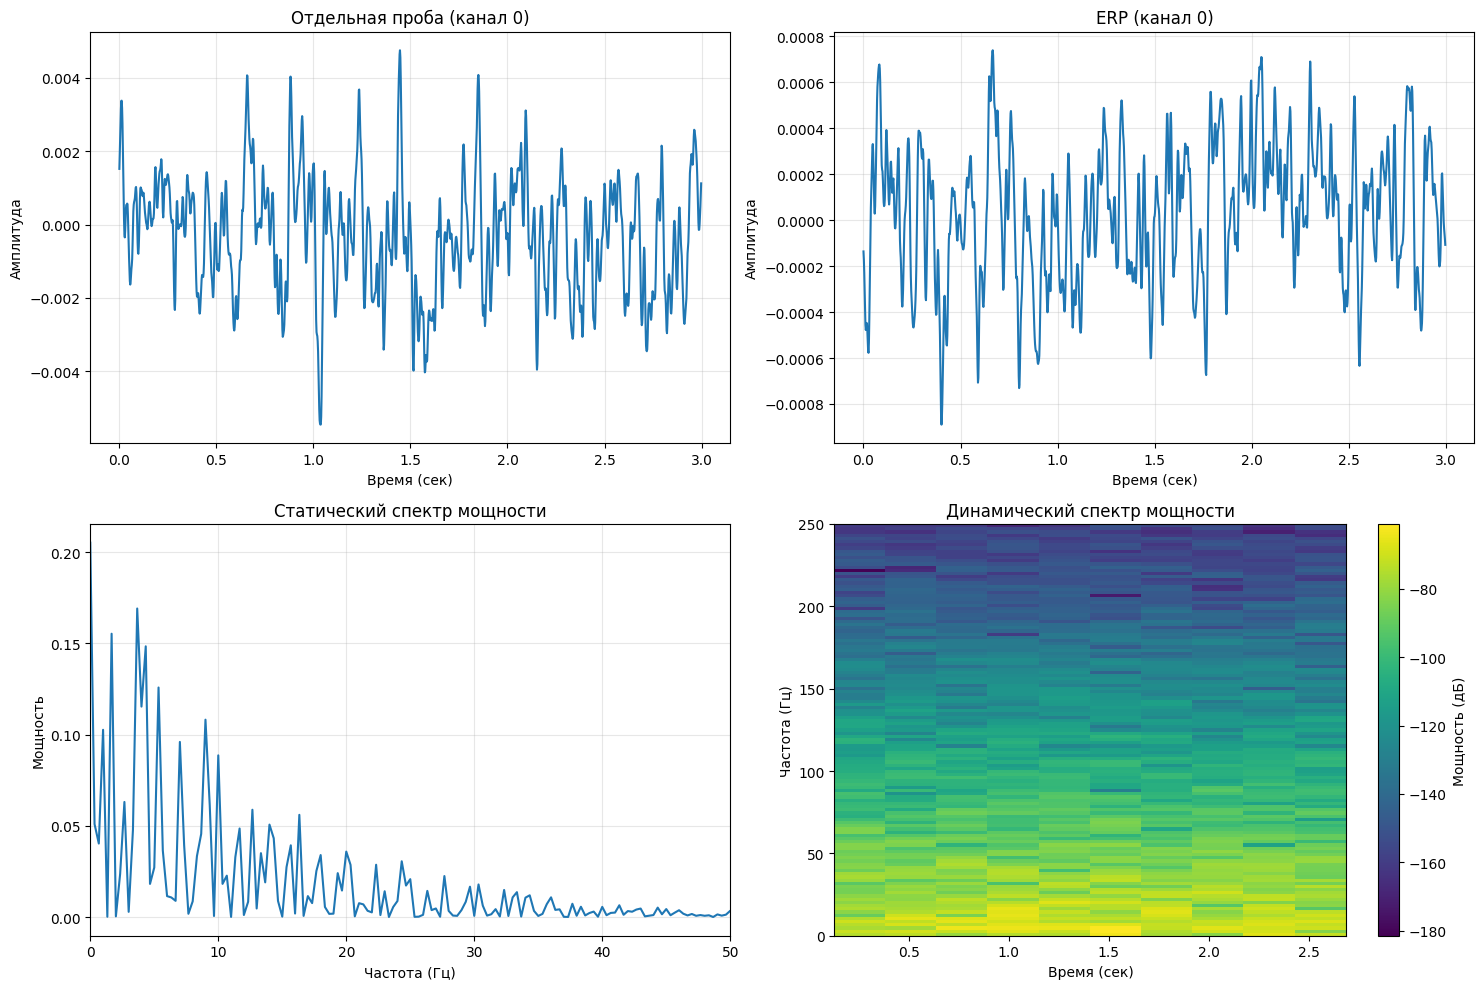

Графики для ed=100


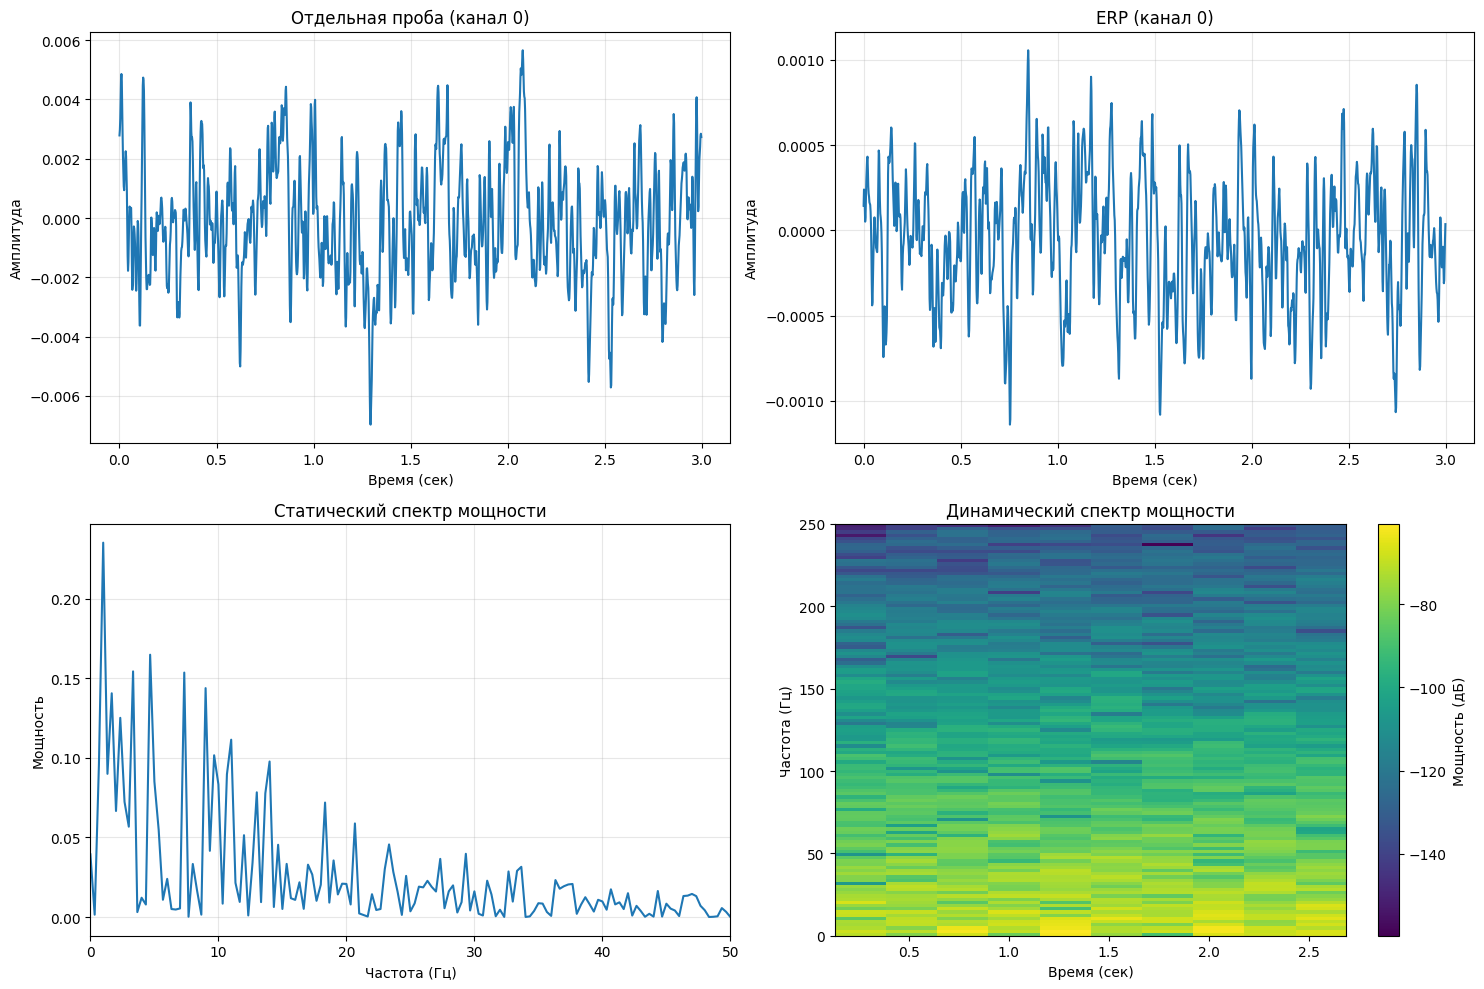

In [ ]:
# 2) Pink noise
print("2) Pink noise")

# Меняем параметры - уменьшаем количество каналов для удобства
EEG['nbchan'] = 4  # Теперь всего 4 канала вместо 23

# Ключевой параметр розового шума - экспоненциальный спад (ed)
# ed контролирует крутизну спада спектра (1/f шум)
ed = [30, 50, 70, 100]  # Можно пробовать разные значения: 10, 30, 100

# Инициализируем данные EEG нулевой матрицей
# Формат: (количество_каналов × временные_точки × пробы)
EEG['data'] = np.zeros((EEG['nbchan'], EEG['pnts'], EEG['trials'])) # Размерность!

for n in ed:
  # Проходим по всем каналам и пробам для генерации розового шума
  for chani in range(EEG['nbchan']):
      for triali in range(EEG['trials']):

          # Генерируем односторонний 1/f амплитудный спектр
          # np.random.rand(EEG['pnts']) - случайные амплитуды от 0 до 1
          # np.exp(-np.arange(EEG['pnts'])/ed) - экспоненциальный спад амплитуд с ростом частоты
          # Результат: низкие частоты имеют большую амплитуду, высокие - меньшую
          as_spectrum = np.random.rand(EEG['pnts']) * np.exp(-np.arange(EEG['pnts'])/n)

          # Создаем Фурье-коэффициенты как амплитуды, умноженные на случайные фазы
          # np.exp(1j * 2 * np.pi * np.random.rand(EEG['pnts'])) - формула Эйлера,
          # домножаем ее на 2pi, чтобы получить значение в радианах
          fc = as_spectrum * np.exp(1j * 2 * np.pi * np.random.rand(EEG['pnts']))

          # Обратное преобразование Фурье для создания шума во временной области
          # np.real() берет только действительную часть (мнимая должна быть близка к 0)
          EEG['data'][chani, :, triali] = np.real(np.fft.ifft(fc))

  # Строим графики используя нашу функцию
  print (f'Графики для ed={n}')
  plot_eeg_data(EEG, channel=0, fig_num=2)

Q: Что больше похоже на реальные данные ЭЭГ - белый или розовый шум? Почему вы так думаете?

Розовый, потому что его статистический спектр мощности уменьщается в зависимости от частоты, что похоже на получаемые в реальности данные.

Q: При каких значениях переменной 'ed' данные выглядят наиболее похожими на реальные данные ЭЭГ?

Наиболее похожие на реальные данные будут получаться при ed примерно равном 50-60.

# 3. Постоянный стационарный сигнал

3) Ongoing stationary


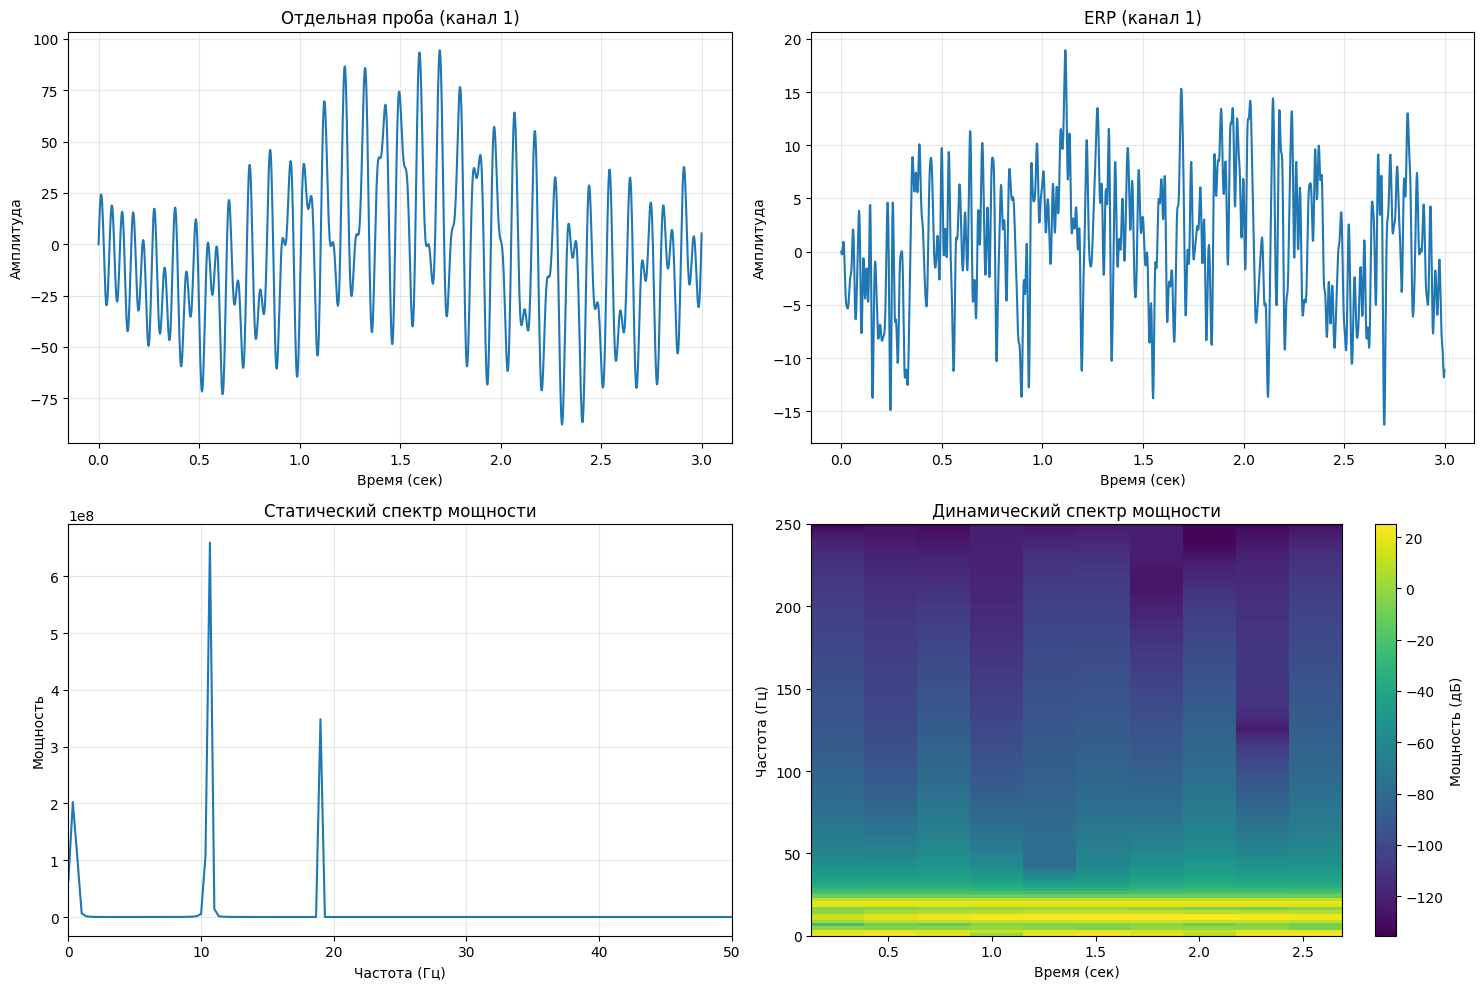

In [ ]:
# 3) Ongoing stationary
print("3) Ongoing stationary")

# Задаем список частот и соответствующих амплитуд для синусоид
# frex - частоты в Герцах: 3 Гц (дельта/тета), 5 Гц (тета), 16 Гц (бета)
# amps - амплитуды в произвольных единицах
frex = [3, 13, 23, 33]  # частоты в Гц
amps = [25, 25, 25, 25]    # амплитуды в условных единицах

# Переинициализируем данные EEG нулевой матрицей
# Очищаем предыдущие данные для нового типа сигнала
EEG['data'] = np.zeros((EEG['nbchan'], EEG['pnts'], EEG['trials']))

# Цикл по всем каналам и пробам для генерации стационарных синусоид
for chani in range(EEG['nbchan']):
    for triali in range(EEG['trials']):
        # Создаем многокомпонентную синусоидальную волну
        # Инициализируем нулевой вектор для накопления суммы синусоид
        sinewave = np.zeros(EEG['pnts'])

        # Проходим по всем заданным частотам и добавляем их в общий сигнал
        for si in range(len(frex)):
            # Для каждой частоты добавляем синусоиду с соответствующей амплитудой
            # Формула: A * sin(2π * f * t)
            # где A - амплитуда, f - частота, t - время
            sinewave += amps[si]*np.sin(2*np.pi*np.random.randn()*frex[si]*EEG['times'])
            #+ 2*np.pi*np.random.randn()

        # Записываем полученную сумму синусоид в данные EEG
        # Все пробы идентичны - сигнал полностью синхронизирован по фазе
        EEG['data'][chani, :, triali] = sinewave

# Строим графики используя нашу функцию
plot_eeg_data(EEG, channel=1, fig_num=3)

Q: Что можно изменить в коде выше, чтобы сделать активность ЭЭГ несинхронизированной по фазе между пробами?

В строке с построением синусоиды ( sinewave += amps[si]*np.sin*(2np.pi*frex[si]*EEG['times']) ) домножить pi на рандомное число.

Q: Какие графики выглядят по-разному для синхронизированных и несинхронизированных по фазе данных? (Подсказка: постройте их на разных рисунках для удобства сравнения.) Удивлены ли вы различиями?

По-разному выглядят графики для вп и для отдельной пробы, так как фазовый сдвиг повлиял на форму графика, который раньше никак не менялся.

Q: Все ли частоты одинаково хорошо представлены на 'статических' и 'динамических' спектрах мощности? Можете ли вы (как?) изменить параметры, чтобы спектральные пики были более или менее видимыми на двух графиках?

Нет, разные частоты представлены по-разному. Чтобы лучше видеть их на графиках, можно уравнять амплитуды между собой и увеличить шаг между частотами.

Q: Как нужно поменять амплитуды, чтобы данные выглядели более биологически правдоподобно? (см. предыдущий пункт)

Сделать так, чтобы была обратная корреляция между частотами и амплитудами.

# 4. Постоянный нестационарный сигнал

4) Ongoing nonstationary


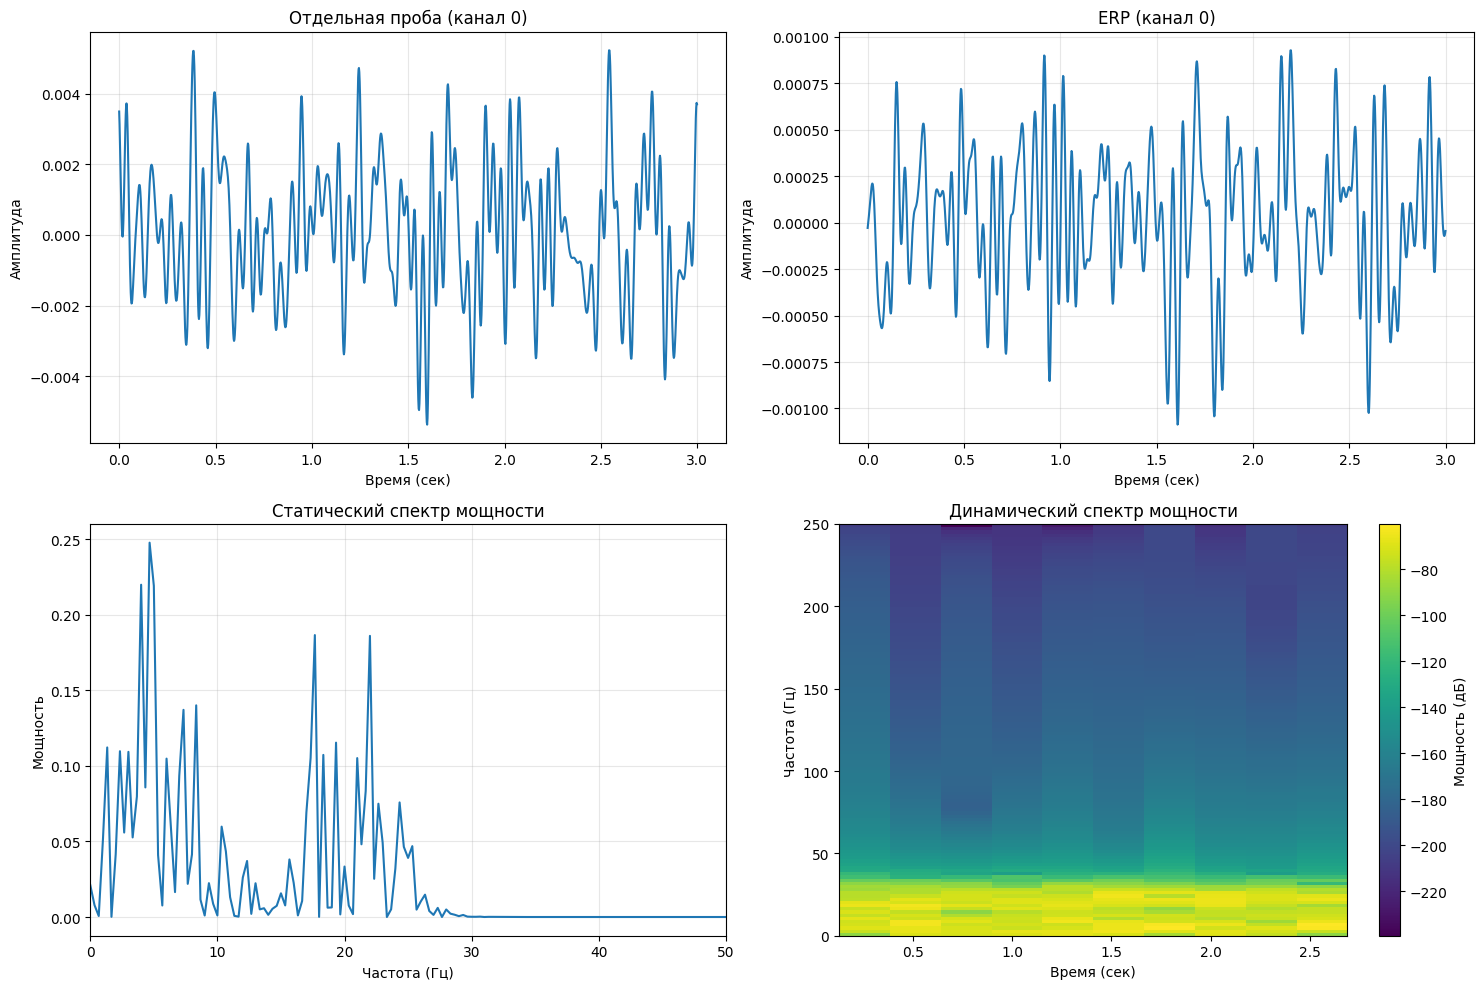

In [ ]:
# 4) Ongoing nonstationary
print("4) Ongoing nonstationary")

# Параметры сигнала в Герцах
peakfreq = 20  # центральная частота пика (альфа/низкая бета активность)
peakfreq2 = 5
fwhm = 10       # полная ширина на половине максимума (ширина полосы)

# Создаем вектор частот для частотной области
# np.linspace создает равномерно распределенные частоты от 0 до частоты дискретизации
hz = np.linspace(0, EEG['srate'], EEG['pnts'])

# Создаем гауссов фильтр в частотной области
# s - нормализованная ширина гауссова фильтра
s = fwhm * (2 * np.pi - 1) / (4 * np.pi)  # нормализованная ширина! А не стандартное отклонение, как во временной области!
# x - смещенные частоты относительно центральной частоты
x = hz - peakfreq                         # смещенные частоты
x2 = hz - peakfreq2
# fg - гауссова функция в частотной области
fg = np.exp(-0.5 * (x / s) ** 2)          # гауссов фильтр
fg2 = np.exp(-0.5 * (x2 / s) ** 2)

# Переинициализируем данные EEG
EEG['data'] = np.zeros((EEG['nbchan'], EEG['pnts'], EEG['trials']))

# Генерируем нестационарный узкополосный сигнал для каждого канала и пробы
for chani in range(EEG['nbchan']):
    for triali in range(EEG['trials']):
        # Создаем Фурье-коэффициенты случайного спектра
        # np.random.rand(EEG['pnts']) - случайные амплитуды
        # np.exp(1j * 2 * np.pi * np.random.rand(EEG['pnts'])) - случайные фазы
        fc = np.random.rand(EEG['pnts']) * np.exp(1j * 2 * np.pi * np.random.rand(EEG['pnts']))

        # Сужаем спектр с помощью гауссова фильтра
        # Умножение на fg оставляет только частоты в узкой полосе вокруг peakfreq
        fc = fc*(fg+fg2)

        # Обратное преобразование Фурье для перехода во временную область
        EEG['data'][chani, :, triali] = np.real(np.fft.ifft(fc))

# Строим графики используя нашу функцию
plot_eeg_data(EEG, channel=0, fig_num=4)

Q: Как FWHM (полная ширина на половине максимума) влияет на результаты? Какое значение более реалистично - большее или меньшее?

Больший FWHM делает фильтры шире, из-за чего распределение частот показывает более широкополосные пики. Это выглядит более реалистично, так как биологический сигнал часто имеет различного рода шумы.

Q: Можете ли вы (как?) изменить код, чтобы получить узкополосную активность в двух разных частотных диапазонах?

Создать два фильтра с разными значениями peakfreq и сложить их между собой перед наложением на данные.

# 5. Всплески активности: ERP

In [ ]:
# 5) Transients #1: Gaussian
print("5) Transients #1: Gaussian")

# Параметры гауссова импульса (в секундах)
peaktime = 1    # Время пика импульса (секунды)
width = 0.1     # Ширина импульса (стандартное отклонение гауссовой кривой)

# Переинициализируем данные EEG
EEG['data'] = np.zeros((EEG['nbchan'], EEG['pnts'], EEG['trials']))

# Генерируем гауссовы транзиенты для каждого канала и пробы
for chani in range(EEG['nbchan']):
    for triali in range(EEG['trials']):
        # Генерируем гауссову функцию во временной области
        # Добавляем случайное смещение времени пика для каждой пробы и домножаем его на 0.25
        #-- просто правдоподобное значение
        trialpeak = peaktime
        # Формула гауссовой функции: exp(-(t - μ)² / (2σ²))
        # где μ = trialpeak (время пика), σ = width (ширина)
        gaus =

        # Данные представляют собой гауссов импульс
        EEG['data'][chani, :, triali] = gaus

# Строим графики используя нашу функцию
plot_eeg_data(EEG, channel=1, fig_num=5)

SyntaxError: invalid syntax (ipython-input-92839711.py, line 19)

Q: Что происходит, когда вы добавляете случайное смещение времени пика (jitter) в каждой пробе? При каком количестве смещения ERP почти исчезает?

# 6. Еще всплески активности: индуцированная осцилляторная активность

In [ ]:
# 6) Transients #2: oscillations w/ Gaussian
print("6) Transients #2: oscillations w/ Gaussian")

# Частота синусоиды
sfreq = 8  # 8 Гц - альфа-диапазон (расслабленное состояние)

# Параметры гауссовой огибающей (в секундах)
peaktime = 1    # Время пика огибающей
width = 0.2     # Ширина огибающей (длительность всплеска)

# Переинициализируем данные EEG
EEG['data'] = np.zeros((EEG['nbchan'], EEG['pnts'], EEG['trials']))

# Генерируем осцилляции с гауссовой огибающей для каждого канала и пробы
for chani in range(EEG['nbchan']):
    for triali in range(EEG['trials']):
        # Генерируем гауссову огибающую во временной области
        # Добавляем небольшой случайный джиттер времени пика
        trialpeak = peaktime + np.random.randn() / 5  # Случайное смещение ±0.2 сек --
        # тоже правдоподобный параметр для осцилляций
        # Гауссова функция: определяет временное окно осцилляций
        gaus = np.exp(-(EEG['times'] - trialpeak) ** 2 / (2 * width ** 2))

        # Генерируем синусоиду с постоянной фазой
        # 8 Гц синусоида: cos(2π × 8 × t)
        sw = np.cos(EEG['times']) # !!!

        # Данные представляют собой синусоиду, умноженную на гауссову огибающую
        # Это создает "всплеск" осцилляций определенной частоты
        EEG['data'][chani, :, triali] = gaus

# Строим графики используя нашу функцию
plot_eeg_data(EEG, channel=1, fig_num=6)

Q: Выглядят ли результаты реалистично? Что можно изменить, чтобы они выглядели еще более похожими на ЭЭГ?

Q: Как можно изменить код, чтобы сделать транзиентный сигнал несинхронизированным по фазе? Какие из трех графиков данных наиболее сильно зависят от синхронизации по фазе?

# 7. Больше упражнений!

1) Добавьте розовый шум в п.5

2) Объедините п.4 и п.6, чтобы создать транзиентный (с гауссовым окном) нестационарный сигнал, т.е. "вспышку" узкополосного нестационарного шума в определенный момент времени!

